## 1. Setup Environment

In [1]:
!pip install datasets gdown pillow

In [2]:
import os, json, gdown, zipfile, shutil
from datasets import Dataset, DatasetDict, Image

In [3]:
OUTPUT_DIR = "/kaggle/working/"
RAW_DATASET_DIR = os.path.join(OUTPUT_DIR, "dataset/raw")
PROCESSED_DATASET_DIR = os.path.join(OUTPUT_DIR, "dataset/processed")

## 2. Download Dataset
### Source: [UIT_DWBD](https://github.com/nghiangh/UIT-HWDB-dataset)

In [4]:
os.makedirs(RAW_DATASET_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATASET_DIR, exist_ok=True)

In [5]:
files = [
    {
        "name": "UIT-HWDB-word",
        "id": "1frQAnh_AViNrNkyRXbbt2DhyGQT-k2dK",
        "filename": "UIT-HWDB-word.zip"
    },
    {
        "name": "UIT-HWDB-line",
        "id": "1Ul6r2lSP24PlZ6Biabhzg5Q2Wg8Qw6E-",
        "filename": "UIT-HWDB-line.zip"
    },
    {
        "name": "UIT-HWDB-paragraph",
        "id": "1aMi0RjLcvvxqogKXE_phyFvWT7xXzdRV",
        "filename": "UIT-HWDB-paragraph.zip"
    }
]

In [6]:
for file_info in files:
    output_path = f"{RAW_DATASET_DIR}/{file_info['filename']}"

    if os.path.exists(output_path):
        print(f"[SKIP] {file_info['name']} is exist.\n")
    else:
        print(f"[DOWNLOADING] {file_info['name']}...")
        try:
            gdown.download(id=file_info['id'], output=output_path, quiet=False)
            with zipfile.ZipFile(output_path, 'r') as zip_ref:
                zip_ref.extractall(RAW_DATASET_DIR)
            os.remove(output_path) 
            print(f"[DONE] {file_info['name']} has finished downloading.\n")
        except Exception as e:
            print(f"[ERROR] {file_info['name']}: {str(e)}\n")
print(f"Raw dataset saved to {RAW_DATASET_DIR}")

[DOWNLOADING] UIT-HWDB-word...


Downloading...
From (original): https://drive.google.com/uc?id=1frQAnh_AViNrNkyRXbbt2DhyGQT-k2dK
From (redirected): https://drive.google.com/uc?id=1frQAnh_AViNrNkyRXbbt2DhyGQT-k2dK&confirm=t&uuid=0a4c4a4e-8565-4b13-ad68-e73fdb95df89
To: /kaggle/working/dataset/raw/UIT-HWDB-word.zip
100%|██████████| 556M/556M [00:08<00:00, 65.7MB/s]


[DONE] UIT-HWDB-word has finished downloading.

[DOWNLOADING] UIT-HWDB-line...


Downloading...
From (original): https://drive.google.com/uc?id=1Ul6r2lSP24PlZ6Biabhzg5Q2Wg8Qw6E-
From (redirected): https://drive.google.com/uc?id=1Ul6r2lSP24PlZ6Biabhzg5Q2Wg8Qw6E-&confirm=t&uuid=1f200dca-bc3e-4fe5-9b48-d4018c0592a1
To: /kaggle/working/dataset/raw/UIT-HWDB-line.zip
100%|██████████| 875M/875M [00:06<00:00, 129MB/s]


[DONE] UIT-HWDB-line has finished downloading.

[DOWNLOADING] UIT-HWDB-paragraph...


Downloading...
From (original): https://drive.google.com/uc?id=1aMi0RjLcvvxqogKXE_phyFvWT7xXzdRV
From (redirected): https://drive.google.com/uc?id=1aMi0RjLcvvxqogKXE_phyFvWT7xXzdRV&confirm=t&uuid=763880d8-62e3-4a94-83b0-32cc97b7aadf
To: /kaggle/working/dataset/raw/UIT-HWDB-paragraph.zip
100%|██████████| 534M/534M [00:04<00:00, 112MB/s]


[DONE] UIT-HWDB-paragraph has finished downloading.

Raw dataset saved to /kaggle/working/dataset/raw


## 3. Load Dataset

In [8]:
def load_data(base_dir):
    data = {
        "train": {"image": [], "text": []},
        "test": {"image": [], "text": []}
    }

    # subsets = ["UIT_HWDB_line", "UIT_HWDB_paragraph", "UIT_HWDB_word"]
    subsets = ["UIT_HWDB_line"]

    for subset in subsets:
        subset_path = f"{base_dir}/{subset}"

        if not os.path.exists(subset_path):
            print(f"Warning: Could not find data directory for {subset}")
            continue

        print(f"Processing {subset} from {subset_path}")

        for split_name, split_key in [("train_data", "train"), ("test_data", "test")]:
            split_path = os.path.join(subset_path, split_name)
            if not os.path.exists(split_path):
                continue

            # Iterate through numbered folders
            for folder_name in os.listdir(split_path):
                folder_path = os.path.join(split_path, folder_name)
                if not os.path.isdir(folder_path):
                    continue

                label_file = os.path.join(folder_path, "label.json")
                if not os.path.exists(label_file):
                    print(f"Warning: No label.json in {folder_path}")
                    continue

                with open(label_file, 'r', encoding='utf-8') as f:
                    try:
                        labels = json.load(f)
                    except json.JSONDecodeError:
                        print(f"Error decoding JSON in {label_file}")
                        continue

                for filename, text in labels.items():
                    image_path = os.path.join(folder_path, filename)
                    if os.path.exists(image_path):
                        data[split_key]["image"].append(image_path)
                        data[split_key]["text"].append(text)
                    else:
                        print(f"Warning: Image {image_path} referenced in label.json but not found.")
    return data

In [9]:
data = load_data(RAW_DATASET_DIR)
train_data = Dataset.from_dict(data["train"]).cast_column("image", Image())
test_data = Dataset.from_dict(data["test"]).cast_column("image", Image())

Processing UIT_HWDB_line from /kaggle/working/dataset/raw/UIT_HWDB_line


In [10]:
print(f"Training samples: {len(train_data)}")
print(f"Testing samples: {len(test_data)}")

Training samples: 7028
Testing samples: 201


## 3. Split Train dataset into Train and Validation
Ratio: 90% train - 10% validation

In [11]:
train_val_split = train_data.train_test_split(test_size=0.1, seed=42)
train_data = train_val_split["train"]
val_data = train_val_split["test"]

Training samples: 6325


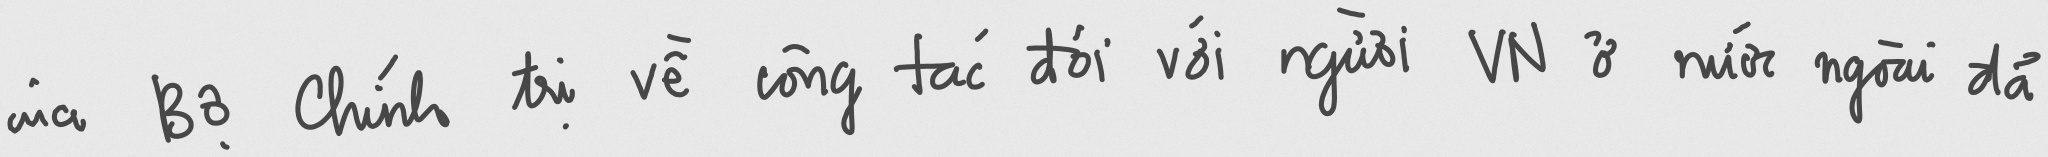

của Bộ Chính trị về công tác đối với người VN ở nước ngoài đã


In [12]:
print(f"Training samples: {len(train_data)}")

sample = train_data[0]
display(sample['image'])
print(sample['text'])

Validation samples: 703


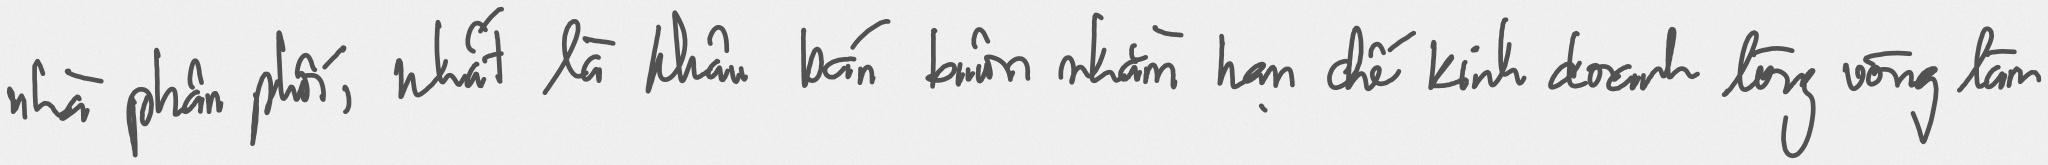

nhà phân phối, nhất là khâu bán buôn nhằm hạn chế kinh doanh lòng vòng làm


In [13]:
print(f"Validation samples: {len(val_data)}")

sample = val_data[0]
display(sample['image'])
print(sample['text'])

Testing samples: 201


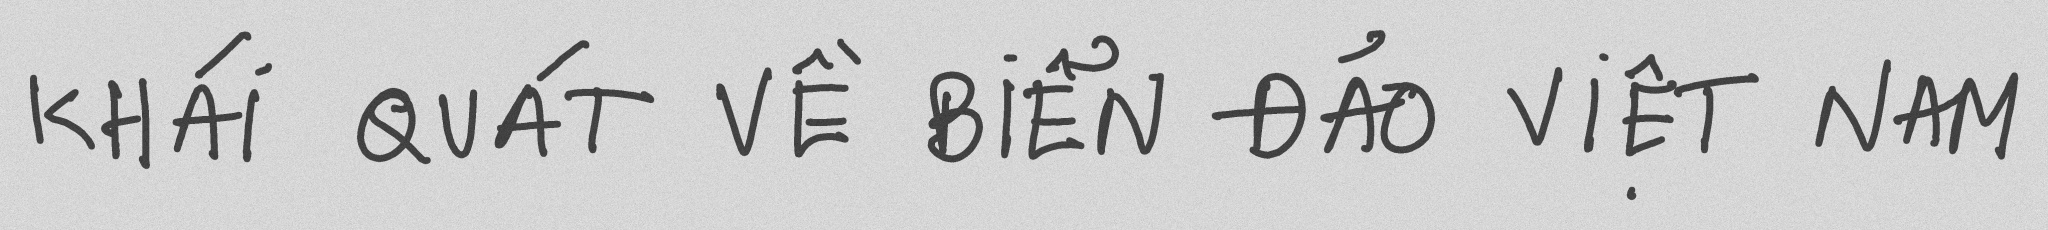

KHÁI QUÁT VỀ BIỂN ĐẢO VIỆT NAM


In [14]:
print(f"Testing samples: {len(test_data)}")

sample = test_data[0]
display(sample['image'])
print(sample['text'])

## 4. Save processed dataset

In [15]:
dataset_dict = DatasetDict({
    "train": train_data,
    "validation": val_data,
    "test": test_data
})

print(dataset_dict)

dataset_dict.save_to_disk(PROCESSED_DATASET_DIR)
print(f"Processed dataset saved to {PROCESSED_DATASET_DIR}")

DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 6325
    })
    validation: Dataset({
        features: ['image', 'text'],
        num_rows: 703
    })
    test: Dataset({
        features: ['image', 'text'],
        num_rows: 201
    })
})


Saving the dataset (0/2 shards):   0%|          | 0/6325 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/703 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/201 [00:00<?, ? examples/s]

Processed dataset saved to /kaggle/working/dataset/processed
